# Tugas 2 Pengantar Sains Data: Preprocessing Data Volume Pengangkutan Sampah
Tahapan Preprocessing:
1. Inspeksi Data & Deskripsi Variabel
2. Pembersihan Noise & Konsistensi Kolom
3. Penanganan / Imputasi Missing Values
4. Ekspor Hasil Preprocessing ke File Excel (`.xlsx`)

In [40]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

## 1. Inspeksi Data & Deskripsi Variabel
Pada tahap ini kita memuat dataset mentah (`.csv`), melihat sampel baris awal, mengecek dimensi data, tipe data tiap kolom, statistik deskriptif awal, serta mendeskripsikan variabel yang ada.

In [41]:
# 1. Membaca CSV mentah dengan pemisah titik koma (;) dan encoding latin1
file_path = "/Users/michaelalex/Desktop/VS Code/Kuliah/Pengantar Sains Data/Tugas/Tugas-2/volume-pengangkutan-sampah-di-kali-sungai-situ-waduk-bulan-januari-tahun-2021 (1) (2).csv"
df_raw = pd.read_csv(file_path, sep=';', encoding='latin1')

# Hapus spasi tersembunyi pada nama kolom (misal ' titik_lokasi ' -> 'titik_lokasi')
df_raw.columns = df_raw.columns.str.strip()

print("=== 1. DIMENSI DATASET MENTAH ===")
print(f"Jumlah Baris : {df_raw.shape[0]:,} baris")
print(f"Jumlah Kolom : {df_raw.shape[1]} kolom\n")

print("=== 2. SAMPEL 10 BARIS PERTAMA DATA MENTAH ===")
display(df_raw.head(10))

print("\n=== 3. INFORMASI TIPE DATA AWAL ===")
df_raw.info()

# Tabel Deskripsi Variabel & Missing Values Awal
deskripsi_map = {
    'bulan': 'Bulan pencatatan data pengangkutan sampah (1 = Januari)',
    'titik_lokasi': 'Nama lokasi kali, sungai, situ, waduk, atau saringan sampah',
    'kecamatan': 'Nama wilayah kecamatan dari titik lokasi',
    'wilayah': 'Nama Kota Administrasi di DKI Jakarta',
    'panjang/luas': 'Ukuran dimensi fisik panjang atau luas titik lokasi',
    'satuan_panjang/luas': 'Satuan ukuran dari kolom panjang/luas (m, Ha, m2, m3, km)',
    'tanggal': 'Tanggal pencatatan harian di bulan Januari (1 s.d. 31)',
    'volume_sampah_perhari(m3)': 'Volume sampah yang diangkut per hari dalam satuan meter kubik (m³)'
}

tabel_inspeksi = pd.DataFrame({
    'Nama Variabel': df_raw.columns,
    'Tipe Data Awal': df_raw.dtypes.values,
    'Non-Null Count': df_raw.notnull().sum().values,
    'Missing (NaN) Awal': df_raw.isnull().sum().values,
    'Persentase NaN (%)': (df_raw.isnull().sum().values / len(df_raw) * 100).round(2),
    'Jumlah Nilai Unik': df_raw.nunique().values,
    'Contoh Isi (Sampel)': [df_raw[col].dropna().unique()[:5] for col in df_raw.columns],
    'Deskripsi Variabel': [deskripsi_map.get(col, '-') for col in df_raw.columns]
})

print("\n=== 4. TABEL DESKRIPSI VARIABEL & INSPEKSI AWAL ===")
display(tabel_inspeksi)

print("\n=== 5. INSPEKSI NOISE & INKONSISTENSI PADA DATA MENTAH ===")
print("a) Variasi nilai 'satuan_panjang/luas' sebelum dibersihkan:")
display(df_raw['satuan_panjang/luas'].fillna('Missing (NaN)').value_counts().to_frame('Jumlah Baris'))

print("\nb) Contoh noise pada kolom 'panjang/luas' (non-numerik):")
noise_panjang = df_raw['panjang/luas'].dropna()[
    pd.to_numeric(df_raw['panjang/luas'].dropna().astype(str), errors='coerce').isna()
]
display(noise_panjang.value_counts().head(15).to_frame('Jumlah Baris'))

print("\nc) Contoh noise pada kolom 'volume_sampah_perhari(m3)' (non-numerik):")
noise_vol = df_raw['volume_sampah_perhari(m3)'].dropna()[
    pd.to_numeric(df_raw['volume_sampah_perhari(m3)'].dropna().astype(str), errors='coerce').isna()
]
display(noise_vol.value_counts().to_frame('Jumlah Baris'))

=== 1. DIMENSI DATASET MENTAH ===
Jumlah Baris : 54,343 baris
Jumlah Kolom : 8 kolom

=== 2. SAMPEL 10 BARIS PERTAMA DATA MENTAH ===


,bulan,titik_lokasi,kecamatan,wilayah,panjang/luas,satuan_panjang/luas,tanggal,volume_sampah_perhari(m3)
0,1,Kali / Sungai Sentiong - Ruas Dewi Sri,Johar Baru,Jakarta Pusat,464,m,1,4
1,1,Kali / Sungai Sentiong - Ruas Abapon,Johar Baru,Jakarta Pusat,464,m,1,4
2,1,Kali / Sungai Sentiong - JL Tanah Tinggi,Johar Baru,Jakarta Pusat,464,m,1,4
3,1,Kali / Sungai Sentiong Jl.Galur - Pombensin,Johar Baru,Jakarta Pusat,606,m,1,4
4,1,Kali / Sungai Sentiong - Jl. Timah,Johar Baru,Jakarta Pusat,310,m,1,7
5,1,PHB Kawi Kawi Bawah,Johar Baru,Jakarta Pusat,620,m,1,1
6,1,PHB Kayu Awet,Johar Baru,Jakarta Pusat,300,m,1,12
7,1,PHB Pulo Gundul,Johar Baru,Jakarta Pusat,500,m,1,1
8,1,PHB Tanah Tinggi XII,Johar Baru,Jakarta Pusat,500,m,1,1
9,1,PHB Bala Dewa,Johar Baru,Jakarta Pusat,330,m,1,1



=== 3. INFORMASI TIPE DATA AWAL ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 54343 entries, 0 to 54342
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   bulan                      54343 non-null  int64 
 1   titik_lokasi               54343 non-null  object
 2   kecamatan                  54343 non-null  object
 3   wilayah                    54343 non-null  object
 4   panjang/luas               53475 non-null  object
 5   satuan_panjang/luas        32388 non-null  object
 6   tanggal                    54343 non-null  int64 
 7   volume_sampah_perhari(m3)  54343 non-null  object
dtypes: int64(2), object(6)
memory usage: 3.3+ MB

=== 4. TABEL DESKRIPSI VARIABEL & INSPEKSI AWAL ===


,Nama Variabel,Tipe Data Awal,Non-Null Count,Missing (NaN) Awal,Persentase NaN (%),Jumlah Nilai Unik,Contoh Isi (Sampel),Deskripsi Variabel
0,bulan,int64,54343,0,0.0,1,[1],Bulan pencatatan data pengangkutan sampah (1 =...
1,titik_lokasi,object,54343,0,0.0,1747,"[Kali / Sungai Sentiong - Ruas Dewi Sri, Kali ...","Nama lokasi kali, sungai, situ, waduk, atau sa..."
2,kecamatan,object,54343,0,0.0,42,"[Johar Baru, Cempaka Putih, Gambir, Kemayoran,...",Nama wilayah kecamatan dari titik lokasi
3,wilayah,object,54343,0,0.0,5,"[Jakarta Pusat, Jakarta Utara, Jakarta Barat, ...",Nama Kota Administrasi di DKI Jakarta
4,panjang/luas,object,53475,868,1.6,442,"[464, 606, 310, 620, 300]",Ukuran dimensi fisik panjang atau luas titik l...
5,satuan_panjang/luas,object,32388,21955,40.4,11,"[m, M³, m², m2, Ha]","Satuan ukuran dari kolom panjang/luas (m, Ha, ..."
6,tanggal,int64,54343,0,0.0,31,"[1, 2, 3, 4, 5]",Tanggal pencatatan harian di bulan Januari (1 ...
7,volume_sampah_perhari(m3),object,54343,0,0.0,59,"[4, 7, 1, 12, -]",Volume sampah yang diangkut per hari dalam sat...



=== 5. INSPEKSI NOISE & INKONSISTENSI PADA DATA MENTAH ===
a) Variasi nilai 'satuan_panjang/luas' sebelum dibersihkan:


,Jumlah Baris
satuan_panjang/luas,
m,29884
Missing (NaN),21955
Ha,1302
M,861
H,93
HA,62
M³,31
m²,31
m2,31



b) Contoh noise pada kolom 'panjang/luas' (non-numerik):


,Jumlah Baris
panjang/luas,
500/3,372
1000/3,341
400/3,310
300/3,279
150/1,279
500/10,248
1000/6,248
500/4,248
1000/10,248



c) Contoh noise pada kolom 'volume_sampah_perhari(m3)' (non-numerik):


,Jumlah Baris
volume_sampah_perhari(m3),
-,15649
,2050
,3
O.5,1


### Deskripsi Variabel:
- **Tanggal / Periode / Tahun / Bulan**: Menunjukkan waktu pencatatan pengangkutan sampah.
- **Wilayah / Kecamatan / Lokasi / TPS**: Menunjukkan lokasi asal atau wilayah administrasi pengangkutan sampah.
- **Jenis Sampah / Armada** *(jika ada)*: Kategori sampah atau jenis kendaraan pengangkut.
- **Volume Sampah (Ton / $m^3$)**: Jumlah muatan/volume sampah yang diangkut (variabel numerik utama).

## 2. Pembersihan Noise & Konsistensi Kolom
Pada tahap ini dilakukan:
1. **Standardisasi nama kolom** (huruf kecil, hapus spasi berlebih, ganti spasi dengan underscore `_`).
2. **Pembersihan string/kategorikal**: Menghapus spasi di awal/akhir (*whitespace*), menyamakan kapitalisasi (*Title Case* / *UPPERCASE*), dan mengganti simbol noise (`"-"`, `"N/A"`, `"?"`, `"null"`, `""`) menjadi `NaN` agar terdeteksi sebagai *missing value*.
3. **Pembersihan kolom numerik (Volume Sampah)**: Menghapus teks satuan yang menempel pada angka (misal `"120 ton"`, `"45,5 m3"`), memperbaiki separator desimal koma menjadi titik, mengubah ke tipe `float`, dan menangani nilai tidak logis (misal nilai negatif `< 0` diubah menjadi `NaN` atau nilai absolut).
4. **Penghapusan baris duplikat**.

In [42]:
# Salin data mentah untuk diproses
df_clean = df_raw.copy()

# Rapikan spasi pada kolom teks utama
for col in ['titik_lokasi', 'kecamatan', 'wilayah']:
    df_clean[col] = df_clean[col].astype(str).str.strip()

# Pastikan string di panjang/luas dan satuan_panjang/luas bersih dari spasi pinggir
pl_str = df_clean['panjang/luas'].astype(str).str.strip()
df_clean['satuan_panjang/luas'] = (
    df_clean['satuan_panjang/luas']
    .astype(str).str.strip()
    .replace({'nan': np.nan, 'None': np.nan, '': np.nan})
)

# -------------------------------------------------------------------------
# 2.1 Memisahkan satuan yang menempel pada kolom 'panjang/luas' (misal 800m, 1Ha)
# -------------------------------------------------------------------------
mask_tempel_m = pl_str.str.match(r'^\d+(\.\d+)?\s*[mM]$', na=False)
mask_tempel_ha = pl_str.str.match(r'^\d+(\.\d+)?\s*[hH][aA]?$', na=False)

df_clean.loc[mask_tempel_m, 'satuan_panjang/luas'] = 'm'
df_clean.loc[mask_tempel_m, 'panjang/luas'] = pl_str[mask_tempel_m].str.replace(r'[mM\s]', '', regex=True)

df_clean.loc[mask_tempel_ha, 'satuan_panjang/luas'] = 'Ha'
df_clean.loc[mask_tempel_ha, 'panjang/luas'] = pl_str[mask_tempel_ha].str.replace(r'[hH][aA]?\s*', '', regex=True)

print(f"[Step 2.1] Satuan menempel dipisahkan: {mask_tempel_m.sum()} baris ('m') dan {mask_tempel_ha.sum()} baris ('Ha').")

# -------------------------------------------------------------------------
# 2.2 Menangani format dimensi 'Panjang/Lebar' (mengandung '/')
# -------------------------------------------------------------------------
pl_str = df_clean['panjang/luas'].astype(str).str.strip()
mask_slash = pl_str.str.contains('/', na=False)

df_clean.loc[mask_slash & df_clean['satuan_panjang/luas'].isna(), 'satuan_panjang/luas'] = 'm'
df_clean.loc[mask_slash, 'panjang/luas'] = pl_str[mask_slash].str.split('/').str[0].str.strip()

print(f"[Step 2.2] Format 'Panjang/Lebar' ('/') berhasil di-parsing: {mask_slash.sum():,} baris.")

# -------------------------------------------------------------------------
# 2.3 Mengubah Noise Tanggal Excel ('Apr-00', 'May-50', '-') menjadi NaN & Konversi ke Float
# -------------------------------------------------------------------------
sebelum_coerce_nan = df_clean['panjang/luas'].isna().sum()
df_clean['panjang/luas'] = pd.to_numeric(df_clean['panjang/luas'], errors='coerce')
sesudah_coerce_nan = df_clean['panjang/luas'].isna().sum()

print(f"[Step 2.3] Noise tanggal Excel & simbol '-' diubah menjadi NaN: {sesudah_coerce_nan - sebelum_coerce_nan} baris.")

# -------------------------------------------------------------------------
# 2.4 Standarisasi 11 Variasi Penulisan Satuan menjadi 5 Satuan Baku
# -------------------------------------------------------------------------
satuan_map = {
    'm': 'm', 'M': 'm',
    'Ha': 'Ha', 'H': 'Ha', 'HA': 'Ha', 'hektar': 'Ha', 'Hektar': 'Ha',
    'm2': 'm2', 'm²': 'm2', 'm\xb2': 'm2',
    'M³': 'm3', 'm³': 'm3', 'M\xb3': 'm3', 'm\xb3': 'm3', 'm3': 'm3',
    'km': 'km', 'KM': 'km', 'Km': 'km'
}
df_clean['satuan_panjang/luas'] = df_clean['satuan_panjang/luas'].map(
    lambda x: satuan_map.get(x, x) if pd.notna(x) else np.nan
)
print("[Step 2.4] Variasi penulisan 'satuan_panjang/luas' diseragamkan.")

# -------------------------------------------------------------------------
# 2.5 Konsistensi Nilai & Satuan Antar-Tanggal pada Titik Lokasi yang Sama
# (Menyebarkan satuan tgl 1 ke tgl 2-31 & memperbaiki 1.36 -> 1360 di Kec. Kebon Jeruk)
# -------------------------------------------------------------------------
df_clean['satuan_panjang/luas'] = (
    df_clean.groupby(['titik_lokasi', 'kecamatan'])['satuan_panjang/luas']
    .transform(lambda s: s.ffill().bfill())
)

df_clean['panjang/luas'] = (
    df_clean.groupby(['titik_lokasi', 'kecamatan'])['panjang/luas']
    .transform('max')
)
print("[Step 2.5] Konsistensi nilai 'panjang/luas' & satuan antar-tanggal per titik lokasi selesai.")

print("\n=== HASIL SEMENTARA SETELAH PEMBERSIHAN 'panjang/luas' & 'satuan_panjang/luas' ===")
display(df_clean[['titik_lokasi', 'kecamatan', 'panjang/luas', 'satuan_panjang/luas', 'tanggal']].head(10))
print("\nDistribusi 'satuan_panjang/luas' saat ini (sebelum imputasi akhir):")
display(df_clean['satuan_panjang/luas'].fillna('Missing (NaN)').value_counts().to_frame('Jumlah Baris'))

[Step 2.1] Satuan menempel dipisahkan: 279 baris ('m') dan 62 baris ('Ha').
[Step 2.2] Format 'Panjang/Lebar' ('/') berhasil di-parsing: 11,749 baris.
[Step 2.3] Noise tanggal Excel & simbol '-' diubah menjadi NaN: 341 baris.
[Step 2.4] Variasi penulisan 'satuan_panjang/luas' diseragamkan.
[Step 2.5] Konsistensi nilai 'panjang/luas' & satuan antar-tanggal per titik lokasi selesai.

=== HASIL SEMENTARA SETELAH PEMBERSIHAN 'panjang/luas' & 'satuan_panjang/luas' ===


/var/folders/z9/rvt8t7mj5qs_qpvgybhnn_bc0000gn/T/ipykernel_26689/2079188555.py:71: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .transform(lambda s: s.ffill().bfill())


,titik_lokasi,kecamatan,panjang/luas,satuan_panjang/luas,tanggal
0,Kali / Sungai Sentiong - Ruas Dewi Sri,Johar Baru,464.0,m,1
1,Kali / Sungai Sentiong - Ruas Abapon,Johar Baru,464.0,m,1
2,Kali / Sungai Sentiong - JL Tanah Tinggi,Johar Baru,464.0,m,1
3,Kali / Sungai Sentiong Jl.Galur - Pombensin,Johar Baru,606.0,m,1
4,Kali / Sungai Sentiong - Jl. Timah,Johar Baru,310.0,m,1
5,PHB Kawi Kawi Bawah,Johar Baru,620.0,m,1
6,PHB Kayu Awet,Johar Baru,300.0,m,1
7,PHB Pulo Gundul,Johar Baru,500.0,m,1
8,PHB Tanah Tinggi XII,Johar Baru,500.0,m,1
9,PHB Bala Dewa,Johar Baru,330.0,m,1



Distribusi 'satuan_panjang/luas' saat ini (sebelum imputasi akhir):


,Jumlah Baris
satuan_panjang/luas,
m,43493
Missing (NaN),9145
Ha,1581
m2,62
m3,31
km,31


In [43]:
# -------------------------------------------------------------------------
# 2.6 Pembersihan Noise pada Kolom 'volume_sampah_perhari(m3)'
# -------------------------------------------------------------------------
vol_str = df_clean['volume_sampah_perhari(m3)'].astype(str).str.strip()

# Koreksi typo huruf 'O.5' menjadi angka '0.5'
jumlah_typo_o = vol_str.str.contains('O|o', na=False).sum()
vol_str = vol_str.str.replace('O', '0', regex=False).str.replace('o', '0', regex=False)

# Konversi simbol strip ('-', '\x97', spasi kosong) menjadi NaN dengan to_numeric
df_clean['volume_sampah_perhari(m3)'] = pd.to_numeric(vol_str, errors='coerce')
jumlah_noise_strip = df_clean['volume_sampah_perhari(m3)'].isna().sum()

print(f"[Step 2.6] Typo 'O.5' -> '0.5' diperbaiki: {jumlah_typo_o} baris.")
print(f"[Step 2.6] Simbol strip ('-', '\\x97', ' ') diubah menjadi NaN: {jumlah_noise_strip:,} baris.")

print("\n=== RINGKASAN TIPE DATA & MISSING VALUES SETELAH SELURUH NOISE DIUBAH KE NaN ===")
ringkasan_setelah_cleaning = pd.DataFrame({
    'Tipe Data': df_clean.dtypes,
    'Jumlah Missing (NaN) Siap Diimputasi': df_clean.isna().sum(),
    'Persentase Missing (%)': (df_clean.isna().sum() / len(df_clean) * 100).round(2)
})
display(ringkasan_setelah_cleaning)

[Step 2.6] Typo 'O.5' -> '0.5' diperbaiki: 1 baris.
[Step 2.6] Simbol strip ('-', '\x97', ' ') diubah menjadi NaN: 17,702 baris.

=== RINGKASAN TIPE DATA & MISSING VALUES SETELAH SELURUH NOISE DIUBAH KE NaN ===


,Tipe Data,Jumlah Missing (NaN) Siap Diimputasi,Persentase Missing (%)
bulan,int64,0,0.00
titik_lokasi,object,0,0.00
kecamatan,object,0,0.00
wilayah,object,0,0.00
panjang/luas,float64,1209,2.22
satuan_panjang/luas,object,9145,16.83
tanggal,int64,0,0.00
volume_sampah_perhari(m3),float64,17702,32.57


## 3. Penanganan / Imputasi Missing Values
Setelah simbol-simbol noise diubah menjadi `NaN`, kita mengecek jumlah *missing values* di setiap kolom dan melakukan imputasi:
- **Kolom Numerik**: Diimputasi menggunakan **Median** (lebih tahan terhadap *outlier* dibanding Mean) atau rata-rata per kelompok wilayah jika tersedia.
- **Kolom Kategorikal**: Diimputasi menggunakan **Modus** (nilai yang paling sering muncul).

In [44]:
print("=== SEBELUM IMPUTASI MISSING VALUES ===")
display(df_clean.isna().sum().to_frame('Jumlah Missing (NaN)'))

# -------------------------------------------------------------------------
# 3.1 Imputasi 'satuan_panjang/luas' dengan Modus ('m')
# -------------------------------------------------------------------------
modus_satuan = df_clean['satuan_panjang/luas'].mode()[0]
jml_missing_satuan = df_clean['satuan_panjang/luas'].isna().sum()
df_clean['satuan_panjang/luas'] = df_clean['satuan_panjang/luas'].fillna(modus_satuan)
print(f"[Step 3.1] {jml_missing_satuan:,} baris kosong pada 'satuan_panjang/luas' diimputasi dengan modus ('{modus_satuan}').")

# -------------------------------------------------------------------------
# 3.2 Imputasi 'panjang/luas' (Lokasi Saringan Sampah) dengan Median per Kecamatan
# -------------------------------------------------------------------------
jml_missing_pl = df_clean['panjang/luas'].isna().sum()
df_clean['panjang/luas'] = df_clean['panjang/luas'].fillna(
    df_clean.groupby('kecamatan')['panjang/luas'].transform('median')
)
# Fallback median global jika ada kecamatan yang seluruhnya NaN
df_clean['panjang/luas'] = df_clean['panjang/luas'].fillna(df_clean['panjang/luas'].median())
print(f"[Step 3.2] {jml_missing_pl:,} baris kosong pada 'panjang/luas' diimputasi dengan Median per Kecamatan.")

# -------------------------------------------------------------------------
# 3.3 Imputasi 'volume_sampah_perhari(m3)' dengan Median per Titik Lokasi & Fallback 0 (MNAR)
# -------------------------------------------------------------------------
jml_missing_vol = df_clean['volume_sampah_perhari(m3)'].isna().sum()

# Isi dengan median harian pada titik_lokasi & kecamatan yang sama
df_clean['volume_sampah_perhari(m3)'] = df_clean['volume_sampah_perhari(m3)'].fillna(
    df_clean.groupby(['titik_lokasi', 'kecamatan'])['volume_sampah_perhari(m3)'].transform('median')
)

# Untuk titik lokasi yang 31 hari penuh berisi '-' (MNAR: tidak ada pengangkutan), isi dengan 0
sisa_mnar_vol = df_clean['volume_sampah_perhari(m3)'].isna().sum()
df_clean['volume_sampah_perhari(m3)'] = df_clean['volume_sampah_perhari(m3)'].fillna(0)

print(f"[Step 3.3] {jml_missing_vol - sisa_mnar_vol:,} baris 'volume_sampah_perhari(m3)' diimputasi dengan Median per Titik Lokasi.")
print(f"[Step 3.3] {sisa_mnar_vol:,} baris lokasi tanpa pengangkutan sebulan penuh (MNAR) diisi dengan 0.")

print("\n=== SETELAH IMPUTASI MISSING VALUES (CEK NaN) ===")
display(df_clean.isna().sum().to_frame('Jumlah Missing (NaN)'))

print("\n=== STATISTIK DESKRIPTIF DATA BERSIH ===")
stats_clean = df_clean[['panjang/luas', 'volume_sampah_perhari(m3)']].agg(['count', 'mean', 'median', 'min', 'max', 'std'])
display(stats_clean)

print("\n=== DISTRIBUSI SATUAN SETELAH PREPROCESSING ===")
display(df_clean['satuan_panjang/luas'].value_counts().to_frame('Jumlah Baris'))

print("\n=== SAMPEL 10 BARIS DATA BERSIH HASIL PREPROCESSING ===")
display(df_clean.head(10))

=== SEBELUM IMPUTASI MISSING VALUES ===


,Jumlah Missing (NaN)
bulan,0
titik_lokasi,0
kecamatan,0
wilayah,0
panjang/luas,1209
satuan_panjang/luas,9145
tanggal,0
volume_sampah_perhari(m3),17702


[Step 3.1] 9,145 baris kosong pada 'satuan_panjang/luas' diimputasi dengan modus ('m').
[Step 3.2] 1,209 baris kosong pada 'panjang/luas' diimputasi dengan Median per Kecamatan.
[Step 3.3] 17,702 baris 'volume_sampah_perhari(m3)' diimputasi dengan Median per Titik Lokasi.
[Step 3.3] 0 baris lokasi tanpa pengangkutan sebulan penuh (MNAR) diisi dengan 0.

=== SETELAH IMPUTASI MISSING VALUES (CEK NaN) ===


,Jumlah Missing (NaN)
bulan,0
titik_lokasi,0
kecamatan,0
wilayah,0
panjang/luas,0
satuan_panjang/luas,0
tanggal,0
volume_sampah_perhari(m3),0



=== STATISTIK DESKRIPTIF DATA BERSIH ===


,panjang/luas,volume_sampah_perhari(m3)
count,54343.000000,54343.000000
mean,929.374652,4.060992
median,700.000000,2.000000
min,0.087500,0.000000
max,36800.000000,152.000000
std,1418.227810,4.969496



=== DISTRIBUSI SATUAN SETELAH PREPROCESSING ===


,Jumlah Baris
satuan_panjang/luas,
m,52638
Ha,1581
m2,62
m3,31
km,31



=== SAMPEL 10 BARIS DATA BERSIH HASIL PREPROCESSING ===


,bulan,titik_lokasi,kecamatan,wilayah,panjang/luas,satuan_panjang/luas,tanggal,volume_sampah_perhari(m3)
0,1,Kali / Sungai Sentiong - Ruas Dewi Sri,Johar Baru,Jakarta Pusat,464.0,m,1,4.0
1,1,Kali / Sungai Sentiong - Ruas Abapon,Johar Baru,Jakarta Pusat,464.0,m,1,4.0
2,1,Kali / Sungai Sentiong - JL Tanah Tinggi,Johar Baru,Jakarta Pusat,464.0,m,1,4.0
3,1,Kali / Sungai Sentiong Jl.Galur - Pombensin,Johar Baru,Jakarta Pusat,606.0,m,1,4.0
4,1,Kali / Sungai Sentiong - Jl. Timah,Johar Baru,Jakarta Pusat,310.0,m,1,7.0
5,1,PHB Kawi Kawi Bawah,Johar Baru,Jakarta Pusat,620.0,m,1,1.0
6,1,PHB Kayu Awet,Johar Baru,Jakarta Pusat,300.0,m,1,12.0
7,1,PHB Pulo Gundul,Johar Baru,Jakarta Pusat,500.0,m,1,1.0
8,1,PHB Tanah Tinggi XII,Johar Baru,Jakarta Pusat,500.0,m,1,1.0
9,1,PHB Bala Dewa,Johar Baru,Jakarta Pusat,330.0,m,1,1.0


## 4. Ekspor Hasil ke File Excel
Menyimpan dataset yang telah melewati seluruh tahapan preprocessing ke dalam file Excel (`.xlsx`).

✅ File Excel berhasil disimpan: Volume_Pengangkutan_Sampah_Januari_2021_Rapi.xlsx


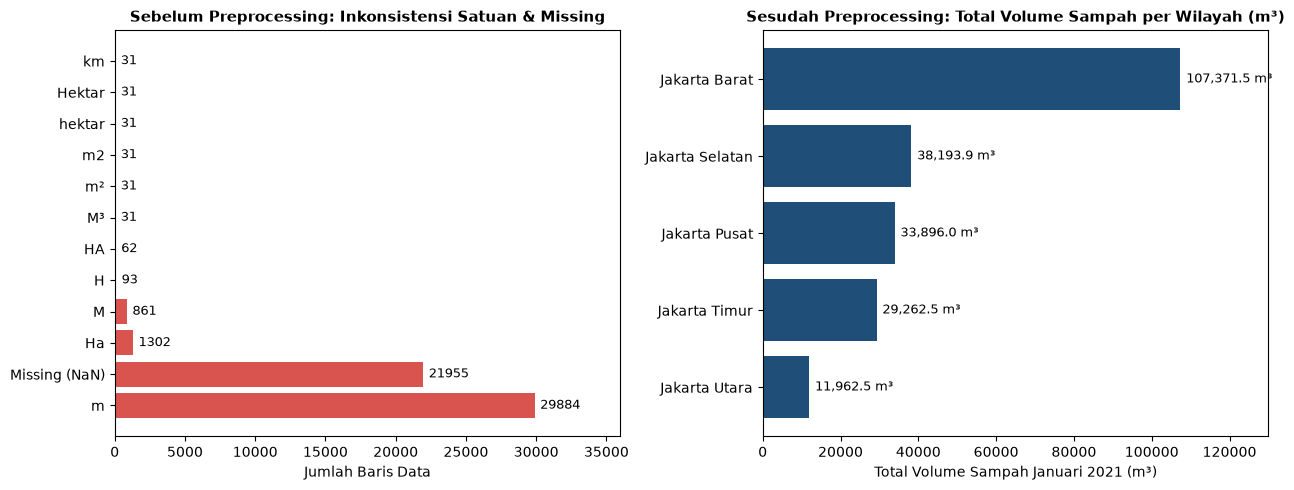

In [45]:
# 1. Simpan ke File Excel (2 Sheet: Data Bersih & Data Mentah)
output_excel = "Volume_Pengangkutan_Sampah_Januari_2021_Rapi.xlsx"

with pd.ExcelWriter(output_excel) as writer:
    df_clean.to_excel(writer, sheet_name='Data_Bersih_Preprocessed', index=False)
    df_raw.to_excel(writer, sheet_name='Data_Mentah_Terpisah_Kolom', index=False)

print(f"✅ File Excel berhasil disimpan: {output_excel}")

# 2. Visualisasi Perbandingan Sebelum vs Sesudah Preprocessing
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Plot Kiri: Inkonsistensi Satuan & Missing Sebelum Preprocessing
raw_satuan = df_raw['satuan_panjang/luas'].fillna('Missing (NaN)').value_counts()
axes[0].barh(raw_satuan.index.astype(str), raw_satuan.values, color='#d9534f')
axes[0].set_title('Sebelum Preprocessing: Inkonsistensi Satuan & Missing', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Jumlah Baris Data')
for i, v in enumerate(raw_satuan.values):
    axes[0].text(v + 400, i, str(v), va='center', fontsize=9)
axes[0].set_xlim(0, 36000)

# Plot Kanan: Total Volume Sampah per Wilayah Sesudah Preprocessing
wilayah_vol = df_clean.groupby('wilayah')['volume_sampah_perhari(m3)'].sum().sort_values()
axes[1].barh(wilayah_vol.index, wilayah_vol.values, color='#1f4e78')
axes[1].set_title('Sesudah Preprocessing: Total Volume Sampah per Wilayah (m³)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Total Volume Sampah Januari 2021 (m³)')
for i, v in enumerate(wilayah_vol.values):
    axes[1].text(v + 1500, i, f"{v:,.1f} m³", va='center', fontsize=9)
axes[1].set_xlim(0, 130000)

plt.tight_layout()
plt.savefig('ringkasan_preprocessing_soal1_fixed.png', dpi=150)
plt.show()